In [1]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2
import src.rl as rl
import librosa
import matplotlib.pyplot as plt
import datasets
import numpy as np
from IPython.display import Audio

/home/adrianm/Documents/projects/vinyl-record-cleaner/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ds = datasets.load_from_disk('data')
ds

DatasetDict({
    train: Dataset({
        features: ['audio', 'title', 'url', 'artist', 'composer', 'lyricist', 'publisher', 'genres', 'tags', 'released', 'language', 'listens', 'artist_url', 'artist_website', 'album_title', 'album_url', 'license', 'copyright', 'explicit', 'instrumental', 'allow_commercial_use', 'allow_derivatives', 'require_attribution', 'require_share_alike'],
        num_rows: 6332
    })
    test: Dataset({
        features: ['audio', 'title', 'url', 'artist', 'composer', 'lyricist', 'publisher', 'genres', 'tags', 'released', 'language', 'listens', 'artist_url', 'artist_website', 'album_title', 'album_url', 'license', 'copyright', 'explicit', 'instrumental', 'allow_commercial_use', 'allow_derivatives', 'require_attribution', 'require_share_alike'],
        num_rows: 1584
    })
})

In [4]:
training_batch = ds['train']
training_batch.features

{'audio': Audio(sampling_rate=None, decode=True, num_channels=None, stream_index=None),
 'title': Value('string'),
 'url': Value('string'),
 'artist': Value('string'),
 'composer': Value('string'),
 'lyricist': Value('string'),
 'publisher': Value('string'),
 'genres': List(ClassLabel(names=['20th Century Classical', 'Abstract Hip-Hop', 'African', 'Afrobeat', 'Alternative Hip-Hop', 'Ambient', 'Ambient Electronic', 'Americana', 'Asia-Far East', 'Audio Collage', 'Avant-Garde', 'Balkan', 'Banter', 'Be-Bop', 'Big Band/Swing', 'Bigbeat', 'Black-Metal', 'Bluegrass', 'Blues', 'Bollywood', 'Brazilian', 'Breakbeat', 'Breakcore - Hard', 'British Folk', 'Celtic', 'Chamber Music', 'Chill-out', 'Chip Music', 'Chiptune', 'Choral Music', 'Christmas', 'Classical', 'Comedy', 'Compilation', 'Composed Music', 'Contemporary Classical', 'Country', 'Country & Western', 'Cumbia', 'Dance', 'Death-Metal', 'Deep Funk', 'Disco', 'Downtempo', 'Drone', 'Drum & Bass', 'Dubstep', 'Easy Listening', 'Easy Listening: V

In [6]:
audio = training_batch[0]['audio']
samples = audio.get_all_samples()
Audio(samples.data[:, :5*samples.sample_rate], rate=samples.sample_rate)

[Text(0.5, 1.0, 'sample from training batch')]

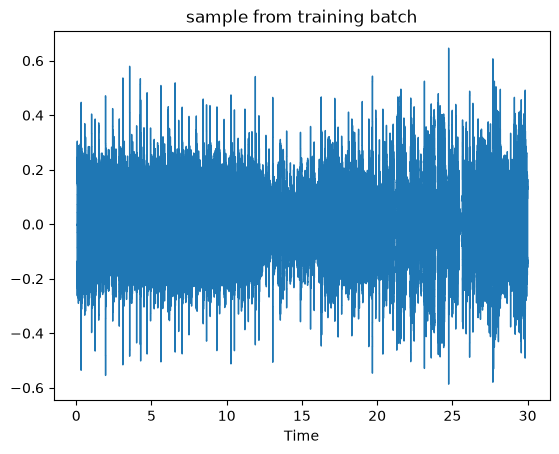

In [7]:
fig, ax = plt.subplots()

y = samples.data.cpu().detach().numpy()
sr = samples.sample_rate
librosa.display.waveshow(y, sr=sr, ax=ax)

# Set the title for the figure
ax.set(title="sample from training batch")